# picomake - wavenet :)

In [45]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import math
%matplotlib inline

In [46]:
# import the dataset

words = open("names.txt", 'r').read().split()
print("length of the dataset - ", len(words))

# build out the vocabulary

letters = sorted(set(letter for x in words for letter in x))
itos = {}
itos[0] = '.'
for number, character in enumerate(letters):
    itos[number+1] = character

stoi = {s:i for i,s in itos.items()}

# shuffle up the words
import random
random.seed(42)
random.shuffle(words)

length of the dataset -  32033


In [47]:
# build out the dataset 
context_size = 8

def build_dataset(words):
    X = []
    Y = []
    for word in words:
        context = [0]*context_size
        for ch in word + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix] # crop and append
            
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

n1 = int(0.8*len(words))
n2 = int(0.9*len(words))
Xtr,  Ytr  = build_dataset(words[:n1])     # 80%
Xdev, Ydev = build_dataset(words[n1:n2])   # 10%
Xte,  Yte  = build_dataset(words[n2:])     # 10%

torch.Size([182625, 8]) torch.Size([182625])
torch.Size([22655, 8]) torch.Size([22655])
torch.Size([22866, 8]) torch.Size([22866])


In [48]:
# pytorch code for init layers of the wavenet

class Linear:
    def __init__(self, fan_in, fan_out, bias = True):
        self.weight = torch.randn((fan_in, fan_out)) / fan_in**0.5
        self.bias = torch.zeros(fan_out) if bias else None

    def __call__(self, x):
        self.out = x@self.weight
        if self.bias is not None:
            self.out+=self.bias
        return self.out

    def parameters(self):
        if self.bias is not None:
            return [self.weight, self.bias]
        else:
            return [self.weight]

class BatchNorm1d:
    def __init__(self, dim, eps = 1e-5, momentum = 0.1):
        self.eps = eps # added to variance before sqrt
        self.momentum = momentum
        self.training = True

        #backprop parameters
        self.bngain = torch.ones(dim)
        self.bnbias = torch.zeros(dim)

        #self running parameters
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)

    def __call__(self, x):

        # calculate the forward pass
        if self.training:
            if x.ndim==2:
                dim = 0
            elif x.ndim==3:
                dim = (0,1)
            xmean = x.mean(dim, keepdim=True)
            xvar = x.var(dim, keepdim = True)
        else:
            xmean = self.running_mean
            xvar = self.running_var
        xhat = (x - xmean) / torch.sqrt(xvar + self.eps) #normalise to unit std deviation and zero mean
        self.out = self.bngain * xhat + self.bnbias

        # update running values

        if self.training:
            with torch.no_grad():
                self.running_mean = (1-self.momentum)*self.running_mean + self.momentum * xmean
                self.running_var = (1-self.momentum)*self.running_var + self.momentum * xvar
        return self.out

    def parameters(self):
        return [self.bnbias, self.bngain]

class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out
    def parameters(self):
        return []

class Embedding:

    def __init__(self, num_embeddings, embedding_dim):
        self.weight = torch.randn((num_embeddings, embedding_dim))
    def __call__(self, ix):
        self.out = self.weight[ix]
        return self.out
    def parameters(self):
        return [self.weight]

class FlattenConsecutive:
  
    def __init__(self, n):
        self.n = n
    
    def __call__(self, x):
        B, T, C = x.shape
        x = x.view(B, T//self.n, C*self.n)
        if x.shape[1] == 1:
            x = x.squeeze(1)
        self.out = x
        return self.out
  
    def parameters(self):
        return []

class Sequential:
  
    def __init__(self, layers):
        self.layers = layers
  
    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        self.out = x
        return self.out
    
    def parameters(self):
        # get parameters of all layers and stretch them out into one list
        return [p for layer in self.layers for p in layer.parameters()]

In [49]:
torch.manual_seed(42); # seed rng for reproducibility

In [50]:
# original network

n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 300 # the number of neurons in the hidden layer of the MLP
vocab_size = 27
model = Sequential([
   Embedding(vocab_size, n_embd),
   FlattenConsecutive(8), 
   Linear(n_embd * 8, n_hidden, bias=False),
   BatchNorm1d(n_hidden), 
   Tanh(),
   Linear(n_hidden, vocab_size),
])

# parameter init
with torch.no_grad():
   model.layers[-1].weight *= 0.1 # last layer make less confident

parameters = model.parameters()
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
   p.requires_grad = True

32997


In [51]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,))
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y
  
  # forward pass
  logits = model(Xb)
  loss = F.cross_entropy(logits, Yb) # loss function
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update: simple SGD
  lr = 0.1 if i < 150000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

      0/ 200000: 3.3068
  10000/ 200000: 2.4424
  20000/ 200000: 2.1992
  30000/ 200000: 2.0833
  40000/ 200000: 2.0246
  50000/ 200000: 2.3545
  60000/ 200000: 2.0951
  70000/ 200000: 2.3598
  80000/ 200000: 1.9663
  90000/ 200000: 1.7205
 100000/ 200000: 2.1300
 110000/ 200000: 1.8303
 120000/ 200000: 1.8676
 130000/ 200000: 2.3447
 140000/ 200000: 2.2823
 150000/ 200000: 1.8470
 160000/ 200000: 1.7114
 170000/ 200000: 2.3682
 180000/ 200000: 1.8341
 190000/ 200000: 1.8881


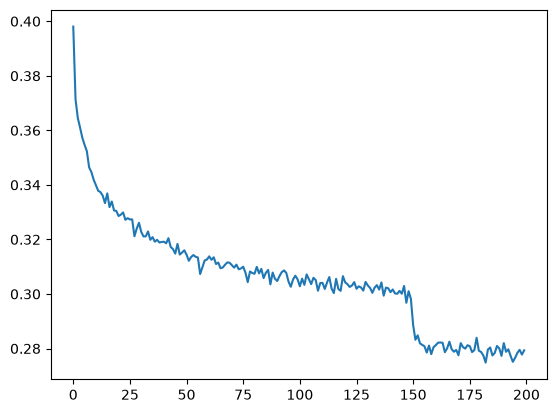

In [52]:
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1))

In [53]:
# put layers into eval mode (needed for batchnorm especially)
for layer in model.layers:
  layer.training = False

In [54]:
# evaluate the loss
@torch.no_grad() # this decorator disables gradient tracking inside pytorch
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  logits = model(x)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 1.8677643537521362
val 2.00728702545166


In [55]:
# sample from the model
for _ in range(20):
    
    out = []
    context = [0] * context_size # initialize with all ...
    while True:
      # forward pass the neural net
      logits = model(torch.tensor([context]))
      probs = F.softmax(logits, dim=1)
      # sample from the distribution
      ix = torch.multinomial(probs, num_samples=1).item()
      # shift the context window and track the samples
      context = context[1:] + [ix]
      out.append(ix)
      # if we sample the special '.' token, break
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out)) # decode and print the generated word

aire.
zaena.
london.
ales.
joriah.
corter.
ithina.
broon.
tall.
jamaria.
brendyn.
moham.
amariah.
leelyrahe.
jenslee.
caide.
alyssaire.
yurncael.
issabesz.
rohen.
